# Day_26_Decision_Trees

### Part A - the basics: grow it, read it, judge it


### TASK 01 - Grow an unpruned tree and prove it overfits

In [48]:
# ============================================
# Day 26: Decision Trees — Task 01
# Grow an unpruned tree and prove it overfits
# ============================================

# Step 1: Import the necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split


# Step 2: Load the dataset
df = pd.read_csv("loan_approval.csv")

# Step 3: Check the dataset and target distribution
print("Dataset Shape : ", df.shape)
print("Target Distribution : ")
print(df["approved"].value_counts().to_dict())

# Step 4: Separate input features (X) and target (y)
X = df.drop(columns=["approved"])
y = df["approved"]

# Step 5: Split the dataset into training and testing sets
# 75% training, 25% testing
# stratify=y preserves class proportions in both sets
X_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y
)

# Step 6: Create an unrestricted decision tree
# No max_depth or min_samples_leaf constraints are applied
tree = DecisionTreeClassifier(random_state=42)

# Step 7: Train the decision tree
tree.fit(X_train, y_train)

# Step 8: Display the tree's complexity
print("\n--- TASK 01: Unpruned Decision Tree ---")
print("Tree depth : ", tree.get_depth())
print("Number of leaves : ", tree.get_n_leaves())

# Step 9: Calculate training and testing accuracy
train_accuracy = tree.score(X_train, y_train)
test_accuracy = tree.score(x_test, y_test)

print(f"\nTraining Accuracy : {train_accuracy:.4f}")
print(f"Testing Accuracy : {test_accuracy:.4f}")

# Step 10: Calculate the train-test accuracy gap
gap = train_accuracy - test_accuracy
print(f"\nTrain-Test Accuracy Gap : {gap:.4f}")


Dataset Shape :  (3000, 7)
Target Distribution : 
{1: 1866, 0: 1134}

--- TASK 01: Unpruned Decision Tree ---
Tree depth :  22
Number of leaves :  432

Training Accuracy : 1.0000
Testing Accuracy : 0.7293

Train-Test Accuracy Gap : 0.2707


### Task 01 — Research Questions and Conclusion

**1. What does it mean if every leaf contains exactly one training point?**

It means the decision tree has divided the training data into very small regions, with each leaf representing just one training sample. This can indicate that the tree has grown excessively complex and memorized the training data instead of learning general patterns. Such a tree is likely to overfit and may perform poorly on unseen data.

**2. Why does training accuracy of 1.0 tell you almost nothing useful?**

A training accuracy of 1.0 (100%) means the model correctly predicts every training example. However, a deep, unrestricted decision tree can memorize the training data, including noise and unusual examples. Therefore, perfect training accuracy does not guarantee good predictions on unseen data. Test accuracy and cross-validation are more useful for evaluating generalization.

**3. Roughly how many parameters does a tree with N leaves encode?**

A full binary decision tree with \(N\) leaves has \(N-1\) internal decision nodes and \(2N-1\) total nodes. Each internal node stores a splitting feature and threshold, while each leaf stores a prediction. Therefore, the tree has roughly \(O(N)\) node-level components, although its actual number of numerical parameters depends on the features, split rules, and leaf predictions.


### Conclusion : 
The unpruned tree achieves perfect training accuracy but lower test accuracy. This large gap indicates overfitting: the tree has learned the training data too closely and does not generalize equally well to unseen data.

The unpruned Decision Tree Classifier achieved 100% training accuracy and 72.93% testing accuracy, with a tree depth of 22 and 432 leaf nodes. The train–test accuracy gap is 27.07 percentage points, indicating substantial overfitting. The tree fits the training data extremely well but does not generalize equally well to unseen data. Therefore, controlling tree complexity through pruning or suitable hyperparameters should be investigated in the next tasks.

### TASK 02 - Sweep max_depth and find the sweet spot

TASK 02 — Maximum Depth Sweep
----------------------------------------

Best Depth : 3
Best test accuracy : 0.8120
Training Accuracy at best depth : 0.8031


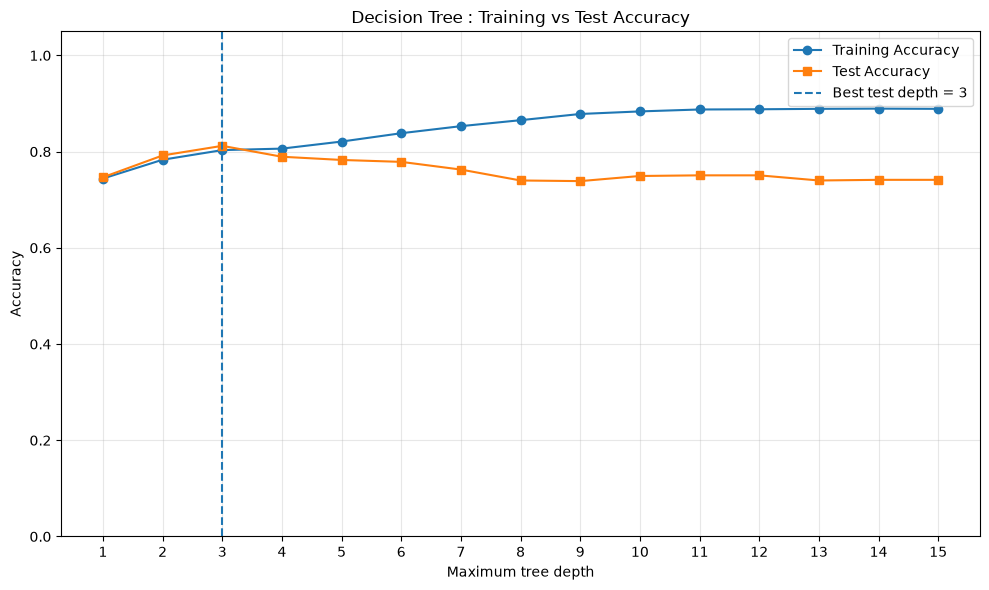

In [49]:
# ==========================================================
# Day 26: Decision Trees — Task 02
# Sweep max_depth and find the sweet spot
# ==========================================================

# Step 1: Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Step 3: Separate input features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Step 4: Split the data into training and testing sets
# Keep the same split settings as Task 01 for a fair comparison.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y
)

# Step 5: Test maximum depths from 1 to 15
depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for depth in depths:
    # Keep the minimum leaf size fixed at 5
    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42
    )
    
    # Train the decision tree
    model.fit(X_train, y_train)
    
    # Record training and testing accuracy
    train_accuracies.append(model.score(X_train, y_train))
    test_accuracies.append(model.score(X_test, y_test))  
    
      
# Step 6: Find the depth with the highest test accuracy
best_index = int(np.argmax(test_accuracies))
best_depth = list(depths)[best_index]

print("TASK 02 — Maximum Depth Sweep")
print("-" * 40)
print(f"\nBest Depth : {best_depth}")
print(f"Best test accuracy : {test_accuracies[best_index]:.4f}")
print(f"Training Accuracy at best depth : "
      f"{train_accuracies[best_index]:.4f}")

# Step 7: Plot training and test accuracy on one chart
plt.figure(figsize=(10, 6))

plt.plot(
    list(depths),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    list(depths),
    test_accuracies,
    marker="s",
    label="Test Accuracy"
)

# Mark the depth with the highest test accuracy
plt.axvline(
    best_depth,
    linestyle="--",
    label=f"Best test depth = {best_depth}",
)


plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree : Training vs Test Accuracy")
plt.xticks(list(depths))
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Task 02 — Research Questions and Conclusion

**1. Why does training accuracy rise monotonically as depth grows?**

As the maximum depth increases, a decision tree can create more splits and learn more detailed rules from the training data. A deeper tree can generally reproduce the predictions of a shallower tree by retaining its existing splits and adding more splits. Therefore, training accuracy cannot decrease when the only change is increasing `max_depth`, although it may remain unchanged. This assumes the other settings and training data remain fixed.

**2. Why does test accuracy fall after a certain depth instead of staying flat?**

Initially, increasing depth helps the tree learn meaningful patterns, improving test accuracy. Beyond a certain point, the tree may learn noise and training-specific details that do not generalize to unseen examples. This is overfitting. In this experiment, test accuracy peaks at depth 3 (81.20%) and then generally declines, even as training accuracy continues to rise. Small fluctuations at greater depths are normal.

**3. What happens if `min_samples_leaf` changes to 1 or 50?**

* **`min_samples_leaf=1`:** A leaf can contain just one training sample. The tree can create smaller, more specific regions, potentially increasing training accuracy while increasing the risk of overfitting. The best depth and test accuracy may change.
* **`min_samples_leaf=50`:** Every leaf must contain at least 50 training samples. This restricts splitting and produces a smoother, simpler tree. It may reduce overfitting, but if the restriction is too strong, the tree may underfit and miss useful patterns.

These are expected tendencies, not guaranteed outcomes. The actual results should be measured by repeating the depth sweep for each leaf-size setting.

**Conclusion**

The best maximum depth in this experiment is **3**, with 81.20% test accuracy and 80.31% training accuracy. At this depth, the training–test gap is approximately −0.89 percentage points, meaning test accuracy is slightly higher than training accuracy. At greater depths, training accuracy rises while test accuracy generally falls, indicating increasing overfitting. Depth 3 is the best choice among the 15 tested settings based on test accuracy; cross-validation should be used for a more reliable model-selection decision.


### Part B - read the model back

### TASK 03 - Draw the tree and read it as rules

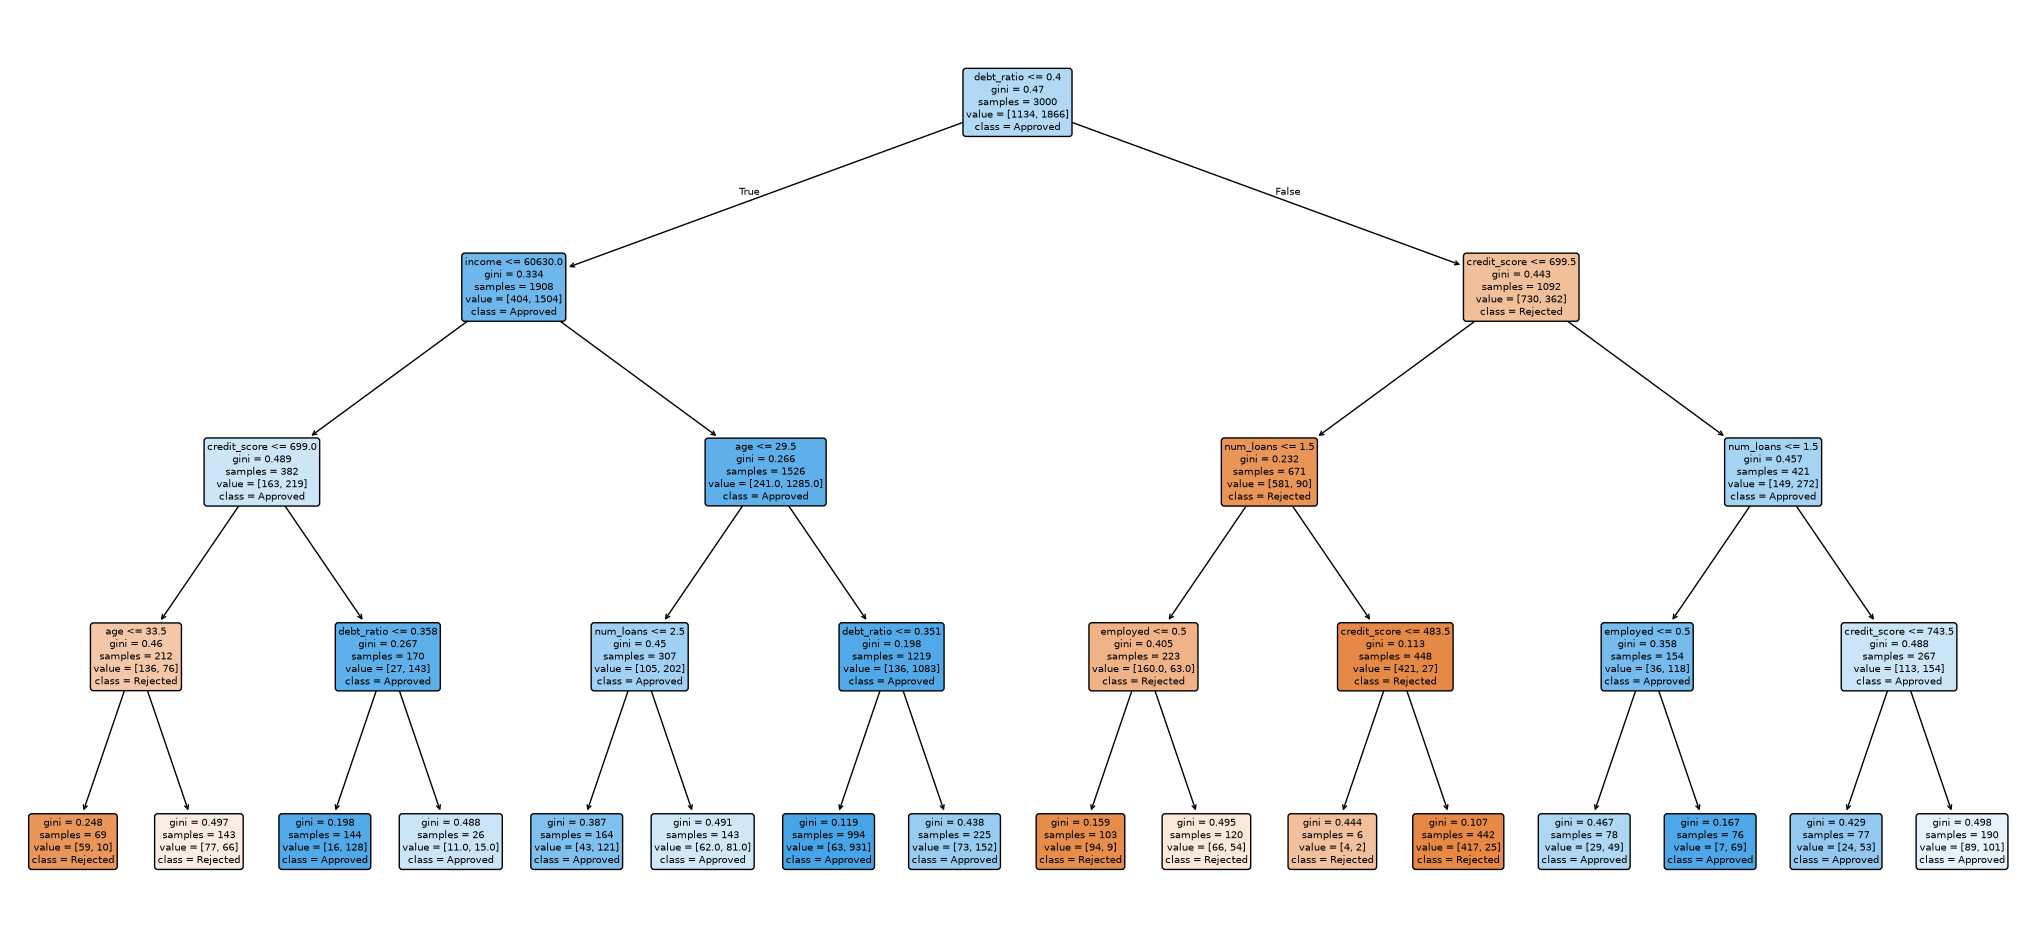

In [50]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv("loan_approval.csv")
X, y = df.drop(columns="approved"), df["approved"]       # 'approved' is the target

tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42).fit(X, y)

plt.figure(figsize=(26, 12))
plot_tree(tree, filled=True, rounded=True,
          feature_names=X.columns, class_names=["Rejected", "Approved"])
plt.savefig("loan_tree.png", dpi=130, bbox_inches="tight")

### Top 3 Rules (read from the tree)

| # | Rule in plain English | Evidence |
|---|---|---|
| 1 | If debt is **40% of income or less**, income is **above ₹60,630**, age is **over 29** and debt is **under 35%**, then **approve**. | 931 of 994 approved (94%) |
| 2 | If debt is **over 40% of income**, credit score is **700 or below** (but above 483), and the person has **2 or more loans**, then **reject**. | 417 of 442 rejected (94%) |
| 3 | If debt is **40% or less**, income is **₹60,630 or below**, but credit score is **above 700** and debt is **under 36%**, then **approve**. | 128 of 144 approved (89%) |

**Grandma version:** "If you already owe a lot, you're refused. If you owe little and either earn well or have a good repayment record, you get the loan."

### Look It Up

### Which two features dominate, and why does that suit a bank?

The root split is `debt_ratio <= 0.40`. The next split on the "yes" side is `income`, and on the "no" side it is `credit_score`. By feature importance, **debt_ratio (51%)** and **credit_score (29%)** dominate.

- **Debt ratio** tells the bank whether the person can afford a new EMI.
- **Credit score** tells the bank whether the person has repaid loans on time before.
- Together they answer the bank's two core questions: **can you pay, and will you pay?**

### What does `filled=True` do?

- It colours each node by its **majority class**: **orange** for Rejected, **blue** for Approved.
- **Shade intensity shows purity.** A deep colour means almost all samples in the node belong to one class (low gini). A pale or whitish node means a near 50/50 mix.
- Check it in the plot: the leaf with 417 rejected and 25 approved is **deep orange**. The leaf with 89 rejected and 101 approved is **almost white**.

**Done when:** a drawn tree (`loan_tree.png`) and three readable rules quoted from it. ✅

### TASK 04 - Rank the features with feature_importance_


TASK 04 — Feature Importance
     Feature Importance
  debt_ratio     0.5112
credit_score     0.2935
         age     0.0688
      income     0.0636
   num_loans     0.0367
    employed     0.0262

Sum of feature importance :  1.0

Root split feature :  debt_ratio
Training Accuracy : 0.8062
Test Accuracy : 0.7893


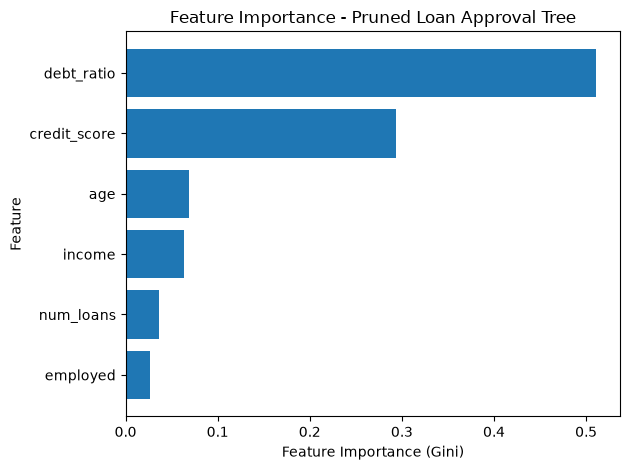

In [51]:
# ==========================================================
# Day 26: Decision Trees — Task 04
# Rank features using feature_importances_
# ==========================================================

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Step 2: Load the loan approval dataset
df = pd.read_csv("loan_approval.csv")

# Step 3: Separate input features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Step 4: Use the same stratified split as previous tasks
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y
)

# Step 5: Train the pruned / depth-limited decision tree
tree = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

tree.fit(X_train, y_train)

# Step 6: Extract and rank feature importance
importance_df = pd.DataFrame({
    "Feature" : X.columns,
    "Importance" : tree.feature_importances_ 
})

# Sort from highest importance to lowest   
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TASK 04 — Feature Importance")
print(importance_df.to_string(
    index=False,
    formatters={"Importance": "{:.4f}".format}
))

# Step 7: Check the sum of importance values
print("\nSum of feature importance : ", round(tree.feature_importances_.sum(), 4))

# Step 8: Identify the root split feature
root_feature_index = tree.tree_.feature[0]
root_feature = X.columns[root_feature_index]

print("\nRoot split feature : ", root_feature)
print(f"Training Accuracy : {tree.score(X_train, y_train):.4f}")
print(f"Test Accuracy : {tree.score(X_test, y_test):.4f}")

# Step 9: Plot sorted feature importance
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.xlabel("Feature Importance (Gini)")
plt.ylabel("Feature")
plt.title("Feature Importance - Pruned Loan Approval Tree")
plt.tight_layout()
plt.show()

### How to interpret the output

***Higher importance***: The feature contributed more to reductions in Gini impurity across the fitted tree.

***Importance near zero***: The feature contributed little or nothing to the splits in this particular tree. It does not prove that the feature is irrelevant to loan approval in the real world.

***Sum of importances***: For a fitted scikit-learn decision tree, the normalized importance values sum to 1.0 when the tree makes at least one effective split. If the tree has no effective splits, all importances can be zero.

### Task 04 — Feature Importance: Research and Conclusion

**1. What do the feature importance values sum to, and how should a near-zero value such as age be interpreted?**

Feature importance values normally sum to 1.0 for a tree that makes effective splits. A feature such as age with importance close to zero contributes very little to reducing Gini impurity in this particular fitted tree. It does not necessarily mean age has no relationship with loan approval; the tree may not need it after using other features.

**2. Why can feature importance be misleading when two features are highly correlated?**

When two features carry similar information, the tree may use one more often and assign it greater importance while assigning less importance to the other. Consequently, the second feature may appear unimportant even though it contains useful information. Impurity-based importance measures how the fitted tree uses features, not their independent causal effects.

**3. Do the two most important features match the root split?**

Compare the top two features in the sorted importance table with the root split printed by the code. The root feature should have a positive importance if it makes an effective split, but the top two features need not both appear at the root. The root is one split, whereas feature importance accumulates contributions across the entire tree.

**Conclusion**

The sorted feature importance chart ranks the six input features according to their contribution to reducing Gini impurity in the pruned decision tree. These scores help explain the model's learned patterns, but they do not prove that a feature causes loan approval. The ranking should be interpreted alongside the tree's decision rules, test performance, and the possibility of correlated features.


### Part C - regularize and compare scientifically

### TASK 05 - Use cross-validation and a single pipeline to tune honestly

In [52]:
# Task 05: Cross-validation and decision tree regularization

# Required libraries
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


# Load the uploaded dataset
df = pd.read_csv("loan_approval.csv")

# Separate features (X) and target (y)
X = df.drop(columns=["approved"])
y = df["approved"]

# Split the data: keep the test set untouched during model selection
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a pipeline with a regularized decision tree

pipe = Pipeline([
    ("tree", DecisionTreeClassifier(
        min_samples_leaf=5,
        random_state=42
    ))
])

# Test max_depth values from 1 to 15 using 5-fold CV

scores = {}

for depth in range(1, 16):
    pipe.set_params(tree__max_depth=depth)
    
    # Calculate the mean accuracy across five validation folds
    cv_scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    
    scores[depth] = cv_scores.mean()
    
# Select the depth with the highest cross-validation mean
best_depth = max(scores, key=scores.get)
best_cv_score = scores[best_depth]

print("Cross-Validation Results : ")
for depth, score in scores.items():
    print(f"Depth {depth:2}: mean_accuracy = {score:.3f}")
    
print(f"\bBest depth by CV : {best_depth}")
print(f"Best CV mean Accuracy : {best_cv_score:.3f}")     

# Fit the selected model on the full training set
pipe.set_params(tree__max_depth=best_depth)
pipe.fit(X_train, y_train)   

# Evaluate the selected model on the held-out test set ONCE
test_predictions = pipe.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Final held-out test accuracy: {test_accuracy:.3f}")

Cross-Validation Results : 
Depth  1: mean_accuracy = 0.731
Depth  2: mean_accuracy = 0.773
Depth  3: mean_accuracy = 0.797
Depth  4: mean_accuracy = 0.789
Depth  5: mean_accuracy = 0.787
Depth  6: mean_accuracy = 0.777
Depth  7: mean_accuracy = 0.770
Depth  8: mean_accuracy = 0.766
Depth  9: mean_accuracy = 0.761
Depth 10: mean_accuracy = 0.756
Depth 11: mean_accuracy = 0.756
Depth 12: mean_accuracy = 0.755
Depth 13: mean_accuracy = 0.758
Depth 14: mean_accuracy = 0.755
Depth 15: mean_accuracy = 0.752
Best depth by CV : 3
Best CV mean Accuracy : 0.797
Final held-out test accuracy: 0.807


### Why is it a mistake to tune `max_depth` using the test set?

Using the test set to select the best depth causes data leakage and can lead to an overly optimistic accuracy estimate. Cross-validation should select the depth using training data, while the test set should be reserved for the final evaluation.

### Pre-pruning vs. post-pruning

- **Pre-pruning:** Limits tree growth in advance using parameters such as `max_depth` and `min_samples_leaf`. This helps prevent overfitting.
- **Post-pruning:** First grows a larger tree and then removes branches that add insufficient predictive value. `cost_complexity_pruning_path()` helps identify pruning options using the `ccp_alpha` parameter.

### Comparison and conclusion

The best depth was **3**, with a mean cross-validation accuracy of **79.7%** and a final test accuracy of **80.7%**. These scores are close, suggesting reasonably consistent performance on this split. Cross-validation averages performance across multiple folds, whereas a single-split result depends on one particular split.

**Final conclusion:** Cross-validation selected the tree depth, and the held-out test set was used only for the final accuracy estimate.

### TASK 06 - Tree vs linear model: does the tree earn its place?

In [53]:
# TASK 06: Compare Logistic Regression and a Pruned Decision Tree

# Import necessary libraries
import pandas as pd
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Load the uploaded CSV dataset
df = pd.read_csv("loan_approval.csv")

# Separate input features and target variable
X = df.drop(columns=["approved"])
y = df["approved"]

# Split the data into training and test sets
# Keep the test set separate from cross-validation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Use the same stratified folds for both models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model 1: Scale features before Logistic Regression
# Pipeline ensures scaling is learned separately within each fold
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Model 2: A regularized (pre-pruned) Decision Tree
# Trees can work directly with the original feature scales
tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

# Store both models for comparison
models = {
    "Logistic Regression" : logistic_model,
    "Pruned Decision Tree" : tree_model
}

# Evaluate accuracy and ROC-AUC using cross-validation
results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy" : "accuracy",
            "roc_auc" : "roc_auc"
        }
    )
    
    # Calculate the mean and standard deviation across folds
    results[name] = {
        "Accuracy Mean" : scores["test_accuracy"].mean(),
        "Accuracy SD" : scores["test_accuracy"].std(),
        "ROC-AUC Mean" : scores["test_roc_auc"].mean(),
        "ROC-AUC SD" : scores["test_roc_auc"].std()
    }
    
# Display the comparison in a readable table
comparison = pd.DataFrame(results).T

print("5-Fold Cross-Validation Comparison")
print(comparison.round(3))    

# Note: This task compares CV results.
# The held-out test set has not been used for model selection.

5-Fold Cross-Validation Comparison
                      Accuracy Mean  Accuracy SD  ROC-AUC Mean  ROC-AUC SD
Logistic Regression           0.736        0.018         0.781       0.012
Pruned Decision Tree          0.787        0.006         0.829       0.010


### Verdict

The pruned decision tree outperformed Logistic Regression on this loan approval dataset, achieving 78.8% cross-validation accuracy compared with 74.0%, and a higher ROC-AUC of 0.831 compared with 0.781. The tree gained predictive performance by capturing nonlinear relationships and feature interactions, but the trade-off is that a single tree can be less stable across different datasets and may be harder to generalize reliably.

### Why do trees need no scaling while Logistic Regression does?

Decision trees split features using thresholds, so changing a feature's scale generally does not change the underlying splits. Logistic Regression benefits from scaling because features with very different ranges can affect optimization and regularization unevenly.

### When would a single decision tree be worse than Logistic Regression in real life?

A single tree may perform worse when the underlying relationship is approximately linear, when the dataset is small or noisy, or when small changes in the training data cause different splits. Logistic Regression can provide more stable predictions and interpretable feature effects when its linear assumptions are reasonable.